# Phase 4: Baseline models (FD001)

**Goal:** find out how well simple models predict remaining life on NASA's official test engines. Every later model (Phase 5 deep learning) has to beat these numbers, by more than chance, to earn its place.

Training and scoring happen in `models/baselines.py`; this notebook reads its saved results. `python -m models.verify_baselines` rechecks every number independently (12/12 checks).

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid")

res = json.loads((ROOT / "models/results_phase4.json").read_text())
preds = pd.read_csv(ROOT / "models/predictions_phase4.csv")
imp = pd.read_csv(ROOT / "models/importance_phase4.csv")
print(res["protocol"])

settings chosen on 20 validation engines; refit on all 100 training engines; test set scored once at each engine's last observed cycle; true RUL capped at 125


## 4.1 The protocol: why the test set is touched only once

**Concept:** settings (Ridge's penalty, XGBoost's tree depth and number of trees) are chosen on the **20 validation engines**. Each model is then refit on **all 100 training engines** and scored **once** on the **100 test engines**, at each engine's last observed cycle.

**Why:** if you keep adjusting a model until the test score looks good, the test score stops being an honest estimate. Using it once keeps it honest.

## 4.2 The two metrics

- **RMSE**: the typical prediction error, in cycles.
- **PHM08 score** (NASA's): with d = predicted - true, a *late* prediction (d > 0, the engine fails sooner than predicted) costs e^(d/10) - 1, while an *early* one costs e^(-d/13) - 1. Late errors are punished more because they mean an in-service failure.

True RUL is capped at 125 for scoring, the same cap used in training. The results file also reports scores against NASA's uncapped values.

In [2]:
rows = []
for name, r in res["models"].items():
    rows.append({"model": name, "validation RMSE": r["val_rmse"], "test RMSE": r["rmse"],
                 "95% interval": f"{r['rmse_ci95'][0]:.1f}-{r['rmse_ci95'][1]:.1f}", "MAE": r["mae"],
                 "PHM08": r["phm"], "late predictions": f"{r['late_share']:.0%}",
                 "seed spread (sd)": r.get("seed_test_rmse_std", np.nan)})
table = pd.DataFrame(rows).round(2)
table

,model,validation RMSE,test RMSE,95% interval,MAE,PHM08,late predictions,seed spread (sd)
0,Fleet average,41.72,41.94,37.4-46.3,34.83,33354.47,50%,NaN
1,"Ridge, raw sensors (14)",19.90,20.59,17.8-23.3,16.37,1223.93,58%,NaN
2,"Ridge, all 168 features",16.27,16.28,14.0-18.4,12.96,464.68,51%,NaN
3,"XGBoost, all 168 features",13.20,15.38,12.4-18.2,11.02,587.73,54%,0.20
4,"XGBoost, no FFT (154)",13.59,15.87,12.8-19.0,11.30,557.78,59%,0.31
5,"XGBoost, rolling only, no EMA/FFT (140)",13.63,15.68,12.8-18.6,11.36,522.74,59%,0.13
6,"XGBoost, without s9 and s14 (144)",13.90,15.51,12.5-18.4,11.03,561.26,58%,0.21
7,"XGBoost, raw sensors only (14)",16.82,17.36,14.0-20.5,12.21,1037.64,55%,0.25


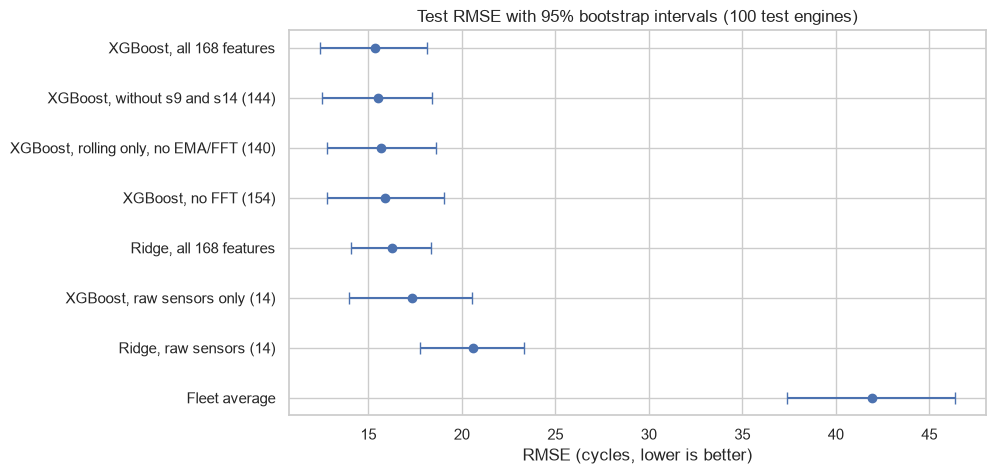

In [3]:
t = pd.DataFrame([{"model": n, "rmse": r["rmse"], "lo": r["rmse_ci95"][0], "hi": r["rmse_ci95"][1]}
                  for n, r in res["models"].items()]).sort_values("rmse")
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(t.rmse, t.model, xerr=[t.rmse - t.lo, t.hi - t.rmse], fmt="o", color="#4C72B0", capsize=4)
ax.invert_yaxis()
ax.set(title="Test RMSE with 95% bootstrap intervals (100 test engines)", xlabel="RMSE (cycles, lower is better)")
fig.savefig(FIG / "fd001_baselines_rmse.png", dpi=150, bbox_inches="tight")

## 4.3 Is a gap real, or luck?

**Concept:** a *paired bootstrap* resamples the same 100 test engines thousands of times and recomputes the gap between two models each time. If the 95% interval of the gap excludes 0, the difference is real; if it includes 0, the test set cannot tell the two models apart.

**Why:** with only 100 test engines, a 1-cycle difference in RMSE can easily be luck. Claiming one model is better without this check is the most common overclaim in student ML projects.

In [4]:
comp = []
for name, c in res["paired_comparisons"].items():
    for metric in ("rmse", "phm"):
        lo, hi = c[metric]["ci"]
        comp.append({"comparison (A vs B)": name, "metric": metric.upper(), "gap A - B": round(c[metric]["diff"], 2),
                     "95% interval": f"{lo:+.2f} to {hi:+.2f}", "A better in": f"{c[metric]['a_wins']:.0%}",
                     "verdict": "A better" if hi < 0 else ("B better" if lo > 0 else "no clear difference")})
pd.DataFrame(comp)

,comparison (A vs B),metric,gap A - B,95% interval,A better in,verdict
0,"XGBoost, all 168 features vs Fleet average",RMSE,-26.56,-32.77 to -20.63,100%,A better
1,"XGBoost, all 168 features vs Fleet average",PHM,-32766.74,-46963.87 to -20066.53,100%,A better
2,"XGBoost, all 168 features vs Ridge, raw sensor...",RMSE,-5.21,-8.64 to -1.93,100%,A better
3,"XGBoost, all 168 features vs Ridge, raw sensor...",PHM,-636.20,-1714.86 to +139.30,93%,no clear difference
4,"XGBoost, all 168 features vs Ridge, all 168 fe...",RMSE,-0.90,-2.81 to +0.95,85%,no clear difference
5,"XGBoost, all 168 features vs Ridge, all 168 fe...",PHM,123.05,-111.38 to +473.31,25%,no clear difference
6,"XGBoost, all 168 features vs XGBoost, no FFT (...",RMSE,-0.50,-1.79 to +0.57,78%,no clear difference
7,"XGBoost, all 168 features vs XGBoost, no FFT (...",PHM,29.95,-195.69 to +279.71,44%,no clear difference
8,"XGBoost, all 168 features vs XGBoost, rolling ...",RMSE,-0.31,-1.61 to +0.85,68%,no clear difference
9,"XGBoost, all 168 features vs XGBoost, rolling ...",PHM,64.99,-159.16 to +327.00,33%,no clear difference


## 4.4 Where the errors are

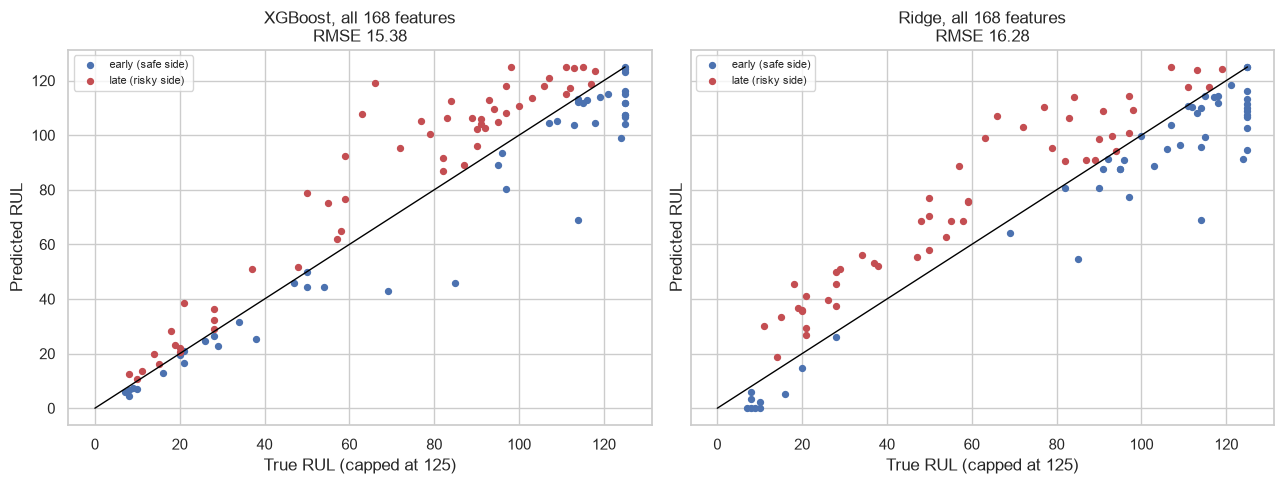

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, m in zip(axes, ["XGBoost, all 168 features", "Ridge, all 168 features"]):
    late = preds[m] > preds.RUL
    ax.scatter(preds.RUL[~late], preds[m][~late], s=18, label="early (safe side)", color="#4C72B0")
    ax.scatter(preds.RUL[late], preds[m][late], s=18, label="late (risky side)", color="#C44E52")
    ax.plot([0, 125], [0, 125], color="black", linewidth=1)
    ax.set(title=f"{m}\nRMSE {res['models'][m]['rmse']:.2f}", xlabel="True RUL (capped at 125)", ylabel="Predicted RUL")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fd001_baselines_pred_vs_true.png", dpi=150, bbox_inches="tight")

In [6]:
m = "XGBoost, all 168 features"
err = (preds[m] - preds.RUL).abs()
bands = pd.cut(preds.RUL, [0, 25, 50, 75, 100, 125], include_lowest=True)
pd.DataFrame({"engines": err.groupby(bands, observed=False).size(),
              "mean absolute error": err.groupby(bands, observed=False).mean().round(1)})

,engines,mean absolute error
RUL,,
"(-0.001, 25.0]",19,3.6
"(25.0, 50.0]",14,6.5
"(50.0, 75.0]",10,24.0
"(75.0, 100.0]",24,15.5
"(100.0, 125.0]",33,10.0


### Near failure, where maintenance decisions are made

Overall scores mix healthy and worn engines. The engines that matter for maintenance are the ones close to failure, so the two tied models are compared again on the 33 test engines with 50 or fewer cycles left.

In [7]:
from models.metrics import mae, paired_bootstrap
near = preds.RUL <= 50
rows = []
for m in ["XGBoost, all 168 features", "Ridge, all 168 features"]:
    d = preds[m][near] - preds.RUL[near]
    rows.append({"model": m, "engines": int(near.sum()), "MAE": round(d.abs().mean(), 1),
                 "mean signed error (+ = late)": round(d.mean(), 1), "late share": f"{(d > 0).mean():.0%}"})
display(pd.DataFrame(rows))
c = paired_bootstrap(preds.RUL[near], preds["XGBoost, all 168 features"][near], preds["Ridge, all 168 features"][near], metric=mae)
print(f"MAE gap XGBoost - Ridge: {c['diff']:+.1f} cycles, 95% interval {c['ci'][0]:+.1f} to {c['ci'][1]:+.1f}, XGBoost better in {c['a_wins']:.0%} of resamples")

,model,engines,MAE,mean signed error (+ = late),late share
0,"XGBoost, all 168 features",33,4.8,1.8,48%
1,"Ridge, all 168 features",33,13.3,9.3,70%


MAE gap XGBoost - Ridge: -8.5 cycles, 95% interval -10.9 to -6.3, XGBoost better in 100% of resamples


['s4_ema', 's4_mean10', 's15_mean10', 's4_mean5', 's11_mean10', 's11_mean5', 's2_mean10', 's15_mean5', 's3_ema', 's9_mean5', 's9_mean10', 's11_ema', 's9_ema', 's3_mean10', 's15_ema']


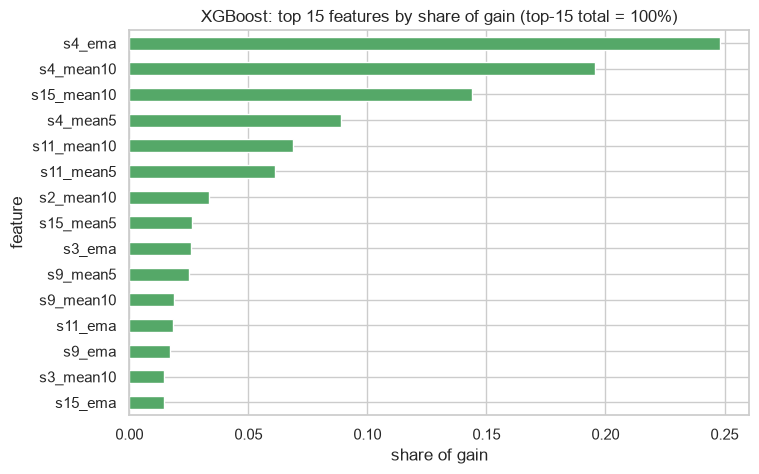

In [8]:
top = imp.head(15).set_index("feature")["gain"]
fig, ax = plt.subplots(figsize=(8, 5))
(top / top.sum())[::-1].plot.barh(ax=ax, color="#55A868")
ax.set(title="XGBoost: top 15 features by share of gain (top-15 total = 100%)", xlabel="share of gain")
fig.savefig(FIG / "fd001_xgb_importance.png", dpi=150, bbox_inches="tight")
print(top.index.tolist())

## What the results say

1. **Feature engineering is the big win, and it is real.** The same linear model goes from 20.59 to 16.28 RMSE when given the Phase 3 features (gap -4.31, interval -6.65 to -2.04: excludes 0, on both metrics).
2. **Over all 100 engines, XGBoost and Ridge on the same features are statistically tied.** XGBoost has the lower RMSE (15.38 vs 16.28) but the gap's interval (-2.81 to +0.95) includes 0, and Ridge has the *better* overall PHM08 score (465 vs 588).
3. **Near failure, XGBoost is clearly better, so it is the published baseline.** On the 33 engines with 50 or fewer cycles left, XGBoost's MAE is 4.8 cycles against Ridge's 13.3, and Ridge is *late* by +9.3 cycles on average (the dangerous direction). The paired interval for this gap excludes 0 (see the table above). The 50-cycle cut-off was chosen after looking at the chart, so it was re-tested at 25, 40, 60 and 75 cycles: XGBoost is clearly better at every one (gaps of 5.9 to 8.5 cycles, all intervals excluding 0); only at 100 cycles, when mostly healthy engines are included, does the gap lose significance. Overall scores hide this because most of Ridge's error sits exactly where decisions are made.
4. **The FFT, EMA and s9/s14 ablations show no measurable effect.** Removing any of them changes RMSE by 0.1-0.5 cycles, inside the test noise and similar to XGBoost's own seed-to-seed spread (0.13-0.31). Phase 3's question is answered: these features neither clearly help nor hurt. They are kept, with that stated.
5. **Validation looks better than test (13.2 vs 15.4 for XGBoost).** Validation scores every cycle of 20 engines, many of them at the 125 cap and easy to predict; the test set scores one point per engine, mostly in the harder degradation phase. The two numbers are not directly comparable, which is why the model choice used validation only to rank settings.
6. **The model is most accurate where it matters most.** For the 19 test engines within 25 cycles of failure, XGBoost's mean absolute error is 3.6 cycles; for 26-50 cycles left it is 6.5. The largest errors (24 cycles) are mid-life, 50-75 cycles left, where wear has only just started to show. Maintenance decisions are made near failure, so this is the right place to be good.
7. **The bar for Phase 5:** a deep model must beat XGBoost's **15.38 RMSE (interval 12.4-18.2) and PHM08 588** with a paired interval that excludes 0. Smaller gains cannot be distinguished on this test set.

## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Fixed the protocol: tune on validation, refit on all training engines, test once | Re-using the test set to tune makes its score dishonest | Settings were picked without seeing test results | Phase 5 follows the same protocol, so the comparison is fair |
| 2 | Used RMSE and the PHM08 score | RMSE treats early and late errors alike; maintenance does not | Rankings can differ by metric: Ridge wins on PHM08, XGBoost on RMSE | Every later model is reported on both |
| 3 | Fleet average baseline | The "no information" answer every model must beat | RMSE 41.9: a single number is useless across 128-362 cycle lifetimes | Confirms the models learn real signal (all beat it by 20+ cycles) |
| 4 | Ridge on raw sensors vs on 168 features | Separates the value of feature engineering from model power | Features alone cut RMSE by 4.3 cycles, a real gap | Feature work from Phase 3 is justified with evidence |
| 5 | XGBoost with 5 seeds and a depth search | Shows how much results move by chance, and picks depth fairly | Seed spread is about 0.2 cycles; depth 5 was best on validation | Phase 5 reports seed spread too |
| 6 | Ablations: no FFT, no EMA, no s9/s14, raw only | Phase 3 left open whether these features help | None of them changes accuracy measurably | Feature set stays as is; honest statement in the docs |
| 7 | Bootstrap intervals and paired comparisons, overall and near failure | 100 test engines is a small sample; gaps can be luck | Overall, XGBoost vs Ridge is a tie; near failure, XGBoost is clearly better (MAE 4.8 vs 13.3) | XGBoost is the published baseline; Phase 5 must win with an interval that excludes 0 |
| 8 | Independent verification (12/12) and float64 fix | Numbers on a resume must be exactly reproducible | A float32/float64 mismatch was caught and fixed | Every phase keeps an independent verifier |

**The habit to keep:** a model is "better" only if the gap survives a fair test on the same engines. Otherwise, report a tie.